# DATA LOADING

In [3]:
import pandas as pd
import os

file_path = "/kaggle/input/datasets/muhammadnajibsalman/idx-80/IDX80 Metadata (1).xlsx"

# Read all sheets → returns dictionary {sheet_name: DataFrame}
sheets_dict = pd.read_excel(file_path, sheet_name=None)

# Access each dataset
for sheet_name, df in sheets_dict.items():
    print(f"Sheet: {sheet_name}")

# Example: store datasets separately
datasets = {}
for sheet_name, df in sheets_dict.items():
    datasets[sheet_name] = df

Sheet: Summary
Sheet: AADI.JK
Sheet: ACES.JK
Sheet: ADMR.JK
Sheet: ADRO.JK
Sheet: AKRA.JK
Sheet: AMMN.JK
Sheet: AMRT.JK
Sheet: ANTM.JK
Sheet: ARTO.JK
Sheet: ASII.JK
Sheet: BBCA.JK
Sheet: BBNI.JK
Sheet: BBRI.JK
Sheet: BBTN.JK
Sheet: BMRI.JK
Sheet: BREN.JK
Sheet: BRMS.JK
Sheet: BRPT.JK
Sheet: BSDE.JK
Sheet: BTPS.JK
Sheet: BUKA.JK
Sheet: BUMI.JK
Sheet: CMRY.JK
Sheet: CPIN.JK
Sheet: CTRA.JK
Sheet: CUAN.JK
Sheet: DSNG.JK
Sheet: DSSA.JK
Sheet: ELSA.JK
Sheet: EMTK.JK
Sheet: ENRG.JK
Sheet: ERAA.JK
Sheet: ESSA.JK
Sheet: EXCL.JK
Sheet: GOTO.JK
Sheet: HEAL.JK
Sheet: HRTA.JK
Sheet: HRUM.JK
Sheet: ICBP.JK
Sheet: INCO.JK
Sheet: INDF.JK
Sheet: INDY.JK
Sheet: INKP.JK
Sheet: INTP.JK
Sheet: ISAT.JK
Sheet: ITMG.JK
Sheet: JPFA.JK
Sheet: JSMR.JK
Sheet: KIJA.JK
Sheet: KLBF.JK
Sheet: KPIG.JK
Sheet: MAPA.JK
Sheet: MAPI.JK
Sheet: MBMA.JK
Sheet: MDKA.JK
Sheet: MEDC.JK
Sheet: MIKA.JK
Sheet: MTEL.JK
Sheet: MYOR.JK
Sheet: NCKL.JK
Sheet: PANI.JK
Sheet: PGAS.JK
Sheet: PGEO.JK
Sheet: PNLF.JK
Sheet: PTBA.JK
Sheet: PTR

In [4]:
summary_df = datasets['Summary']

In [5]:
summary_df

,No,Indeks,Date Started,Company_Name,Sector,Industry,Market_Cap,Beta,Country,Currency,Exchange
0,1,AADI,2024-12-05,NaN,Energy,Thermal Coal,78842278445056,NaN,Indonesia,IDR,JKT
1,2,ACES,2007-11-06,PT Aspirasi Hidup Indonesia Tbk,Consumer Cyclical,Specialty Retail,6094859010048,0.190,Indonesia,IDR,JKT
2,3,ADMR,2022-01-03,PT Alamtri Minerals Indonesia Tbk,Basic Materials,Coking Coal,72770553643008,0.418,Indonesia,IDR,JKT
3,4,ADRO,2008-07-16,PT Alamtri Resources Indonesia Tbk,Energy,Thermal Coal,70273206321152,-0.229,Indonesia,IDR,JKT
4,5,AKRA,2005-09-29,PT AKR Corporindo Tbk,Energy,Oil & Gas Refining & Marketing,27521678573568,-0.464,Indonesia,IDR,JKT
...,...,...,...,...,...,...,...,...,...,...,...
75,76,TLKM,2004-09-28,Perusahaan Perseroan (Persero) PT Telekomunika...,Communication Services,Telecom Services,317989714919424,0.154,Indonesia,IDR,JKT
76,77,TOWR,2010-03-08,PT Sarana Menara Nusantara Tbk.,Real Estate,Real Estate Services,28640098123776,-0.007,Indonesia,IDR,JKT
77,78,UNTR,2000-09-05,PT United Tractors Tbk,Basic Materials,Other Industrial Metals & Mining,111826419318784,-0.170,Indonesia,IDR,JKT
78,79,UNVR,2003-09-03,PT Unilever Indonesia Tbk,Consumer Defensive,Household & Personal Products,72923964506112,0.366,Indonesia,IDR,JKT


In [6]:
import pandas as pd

def clean_sheet(df, sheet_name):
    # Drop useless first column (Unnamed: 0)
    df = df.drop(columns=df.columns[0])

    # Drop first two rows (Ticker + Date row)
    df = df.iloc[2:].reset_index(drop=True)

    # Rename columns
    df = df.rename(columns={
        'Price': 'date',
        'Close': 'close',
        'High': 'high',
        'Low': 'low',
        'Open': 'open',
        'Volume': 'volume'
    })

    # Convert types
    df['date'] = pd.to_datetime(df['date'])

    numeric_cols = ['close', 'high', 'low', 'open', 'volume']
    df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')

    # Add stock identifier
    df['ticker'] = sheet_name

    return df

In [7]:
xls = pd.ExcelFile(file_path)
all_data = []

for sheet in xls.sheet_names[1:]:
    df = pd.read_excel(xls, sheet_name=sheet)
    clean_df = clean_sheet(df, sheet)
    all_data.append(clean_df)

# Combine all stocks
combined_df = pd.concat(all_data, ignore_index=True)

print(combined_df.head())

        date        close          high          low         open     volume  \
0 2024-12-05  6241.059082   6241.059082  6241.059082  6241.059082     459400   
1 2024-12-06  7484.578125   7484.578125  7484.578125  7484.578125     446600   
2 2024-12-09  8962.723633   8962.723633  8962.723633  8962.723633   43658100   
3 2024-12-10  9643.139648  10675.495231  9009.648723  9854.303290  228636600   
4 2024-12-11  9009.649414   9807.378789  8986.186785  9643.140388  100219900   

    ticker  
0  AADI.JK  
1  AADI.JK  
2  AADI.JK  
3  AADI.JK  
4  AADI.JK  


In [8]:
combined_df.shape, combined_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 325319 entries, 0 to 325318
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    325319 non-null  datetime64[ns]
 1   close   325319 non-null  float64       
 2   high    325319 non-null  float64       
 3   low     325319 non-null  float64       
 4   open    325319 non-null  float64       
 5   volume  325319 non-null  int64         
 6   ticker  325319 non-null  object        
dtypes: datetime64[ns](1), float64(4), int64(1), object(1)
memory usage: 17.4+ MB


((325319, 7), None)

In [9]:
combined_df["ticker_clean"] = (
    combined_df["ticker"]
    .str.replace(".JK", "", regex=False)
)

In [10]:
summary_df = datasets["Summary"].copy()

summary_df = summary_df.rename(
    columns={
        "Indeks": "ticker_clean"
    }
)

combined_df = combined_df.merge(
    summary_df[
        [
            "ticker_clean",
            "Sector",
            "Industry",
            "Market_Cap",
            "Beta"
        ]
    ],
    on="ticker_clean",
    how="left"
)

In [11]:
import yfinance as yf
import pandas as pd
import numpy as np

# ============================================================
# DOWNLOAD IHSG (^JKSE)
# ============================================================

ihsg = yf.download(
    "^JKSE",
    start="2010-01-01",
    end=None,
    auto_adjust=False
)

# ============================================================
# FIX MULTIINDEX COLUMNS
# ============================================================

if isinstance(ihsg.columns, pd.MultiIndex):
    ihsg.columns = ihsg.columns.get_level_values(0)

# ============================================================
# RESET INDEX
# ============================================================

ihsg = ihsg.reset_index()

# ============================================================
# RENAME COLUMNS
# ============================================================

ihsg.columns = [
    str(col).lower().replace(" ", "_")
    for col in ihsg.columns
]

# ============================================================
# IHSG FEATURES
# ============================================================

ihsg["ihsg_return"] = np.log(
    ihsg["close"] / ihsg["close"].shift(1)
)

ihsg["ihsg_volatility_20"] = (
    ihsg["ihsg_return"]
    .rolling(20)
    .std()
)

ihsg["ihsg_momentum_20"] = np.log(
    ihsg["close"] / ihsg["close"].shift(20)
)

# ============================================================
# KEEP NEEDED COLUMNS
# ============================================================

ihsg_features = ihsg[[
    "date",
    "ihsg_return",
    "ihsg_volatility_20",
    "ihsg_momentum_20"
]]

# ============================================================
# MERGE TO MAIN DATASET
# ============================================================

combined_df["date"] = pd.to_datetime(combined_df["date"])

combined_df = combined_df.merge(
    ihsg_features,
    on="date",
    how="left"
)

print(combined_df[[
    "date",
    "ihsg_return",
    "ihsg_volatility_20",
    "ihsg_momentum_20"
]].head())

[*********************100%***********************]  1 of 1 completed

        date  ihsg_return  ihsg_volatility_20  ihsg_momentum_20
0 2024-12-05    -0.001838            0.010919         -0.009601
1 2024-12-06     0.009455            0.010195          0.018997
2 2024-12-09     0.007415            0.010238          0.020448
3 2024-12-10     0.002089            0.010199          0.025386
4 2024-12-11     0.001537            0.010090          0.019311


# DATA PREPROCESSING

## Feature Engineering

In [12]:
cdf = combined_df.copy()

In [74]:
# ============================================================
# 1. SORT DATA
# ============================================================

combined_df = cdf.copy()
combined_df = (
    combined_df
    .sort_values(["ticker", "date"])
    .reset_index(drop=True)
)

# ============================================================
# 2. BASIC RETURN FEATURES
# ============================================================

# ---------------------------
# LOG RETURN
# ---------------------------

combined_df["log_return"] = (

    combined_df
    .groupby("ticker")["close"]

    .transform(
        lambda x:
        np.log(x / x.shift(1))
    )
)

# ---------------------------
# LOG VOLUME
# ---------------------------

combined_df["log_volume"] = np.log1p(
    combined_df["volume"]
)

# ---------------------------
# VOLUME CHANGE
# ---------------------------

combined_df["volume_change"] = (

    combined_df
    .groupby("ticker")["log_volume"]

    .diff()
)

# ============================================================
# 3. PRICE ACTION FEATURES
# ============================================================

# ---------------------------
# HIGH LOW SPREAD
# ---------------------------

combined_df["hl_spread"] = (

    (
        combined_df["high"]
        -
        combined_df["low"]
    )

    /

    combined_df["close"]
)


# ============================================================
# 4. ROLLING TREND FEATURES
# ============================================================

windows = [5, 20]

for window in windows:

    # ---------------------------
    # ROLLING MEAN
    # ---------------------------

    combined_df[f"rolling_mean_{window}"] = (

        combined_df
        .groupby("ticker")["log_return"]

        .transform(
            lambda x:
            x.rolling(window).mean()
        )
    )

    # ---------------------------
    # ROLLING STD
    # ---------------------------

    combined_df[f"rolling_std_{window}"] = (

        combined_df
        .groupby("ticker")["log_return"]

        .transform(
            lambda x:
            x.rolling(window).std()
        )
    )

# ============================================================
# 5. RSI FEATURE
# ============================================================

def compute_rsi(
    series,
    window=14
):

    delta = series.diff()

    gain = delta.clip(lower=0)

    loss = -delta.clip(upper=0)

    avg_gain = (
        gain
        .rolling(window)
        .mean()
    )

    avg_loss = (
        loss
        .rolling(window)
        .mean()
    )

    rs = (
        avg_gain
        /
        (avg_loss + 1e-9)
    )

    rsi = (
        100
        -
        (
            100
            /
            (1 + rs)
        )
    )

    return rsi

combined_df["rsi_14"] = (

    combined_df
    .groupby("ticker")["close"]

    .transform(compute_rsi)
)

# NORMALIZE RSI
combined_df["rsi_14"] = (
    combined_df["rsi_14"] / 100
)

# ============================================================
# 6. MACD FEATURE
# ============================================================

def compute_macd(series):

    ema12 = (

        series
        .ewm(
            span=12,
            adjust=False
        )
        .mean()
    )

    ema26 = (

        series
        .ewm(
            span=26,
            adjust=False
        )
        .mean()
    )

    macd = ema12 - ema26

    return macd

combined_df["macd"] = (

    combined_df
    .groupby("ticker")["close"]

    .transform(compute_macd)
)

# NORMALIZED MACD
combined_df["macd_normalized"] = (

    combined_df["macd"]

    /

    combined_df["close"]
)

# ============================================
# ROLLING VOLATILITY
# ============================================

# 10-day volatility
combined_df["volatility_10d"] = (
    combined_df.groupby("ticker")["log_return"]

    .transform(
        lambda x:
        x.rolling(10).std()
    )
)

# 20-day volatility
combined_df["volatility_20d"] = (
    combined_df.groupby("ticker")["log_return"]

    .transform(
        lambda x:
        x.rolling(10).std()
    )
)

# ============================================================
# 11. TARGETS
# ============================================================

# 2 week target
combined_df["future_volatility_10d"] = (

    combined_df
    .groupby("ticker")["log_return"]

    .transform(
        lambda x:
        np.log1p(
            x
            .rolling(window=10)
            .std()
            .shift(-10)
        )
    )
)

# 1 month target
combined_df["future_volatility_1m"] = (

    combined_df
    .groupby("ticker")["log_return"]

    .transform(
        lambda x:
        np.log1p(
            x
            .rolling(window=22)
            .std()
            .shift(-22)
        )
    )
)

# 3 month target
combined_df["future_volatility_3m"] = (

    combined_df
    .groupby("ticker")["log_return"]

    .transform(
        lambda x:
        np.log1p(
            x
            .rolling(window=66)
            .std()
            .shift(-66)
        )
    )
)

# ============================================================
# 12. CLEAN DATA
# ============================================================

combined_df = (

    combined_df

    .replace(
        [np.inf, -np.inf],
        np.nan
    )

    .dropna()

    .reset_index(drop=True)
)

# ============================================================
# 13. ENCODING
# ============================================================

from sklearn.preprocessing import LabelEncoder

# ---------------------------
# TICKER
# ---------------------------

ticker_encoder = LabelEncoder()

combined_df["ticker_encoded"] = (

    ticker_encoder
    .fit_transform(
        combined_df["ticker"]
    )
)

num_stocks = (
    combined_df["ticker_encoded"]
    .nunique()
)

# ---------------------------
# SECTOR
# ---------------------------

sector_encoder = LabelEncoder()

combined_df["sector_encoded"] = (

    sector_encoder
    .fit_transform(
        combined_df["Sector"]
    )
)

num_sectors = (
    combined_df["sector_encoded"]
    .nunique()
)

# ---------------------------
# INDUSTRY
# ---------------------------

industry_encoder = LabelEncoder()

combined_df["industry_encoded"] = (

    industry_encoder
    .fit_transform(
        combined_df["Industry"]
    )
)

num_industries = (
    combined_df["industry_encoded"]
    .nunique()
)

print("Stocks:", num_stocks)
print("Sectors:", num_sectors)
print("Industries:", num_industries)

Stocks: 80
Sectors: 11
Industries: 35


# TRAINING

## Config

In [75]:
# ============================================================
# MULTI HORIZON CONFIG
# ============================================================

MULTI_TARGET_COLS = [

    "future_volatility_10d",
    "future_volatility_1m",
    "future_volatility_3m"
]

LOOKBACK = 90

FEATURE_COLS = [

    "log_return",

    "volume_change",

    "volatility_10d",
    "volatility_20d",

    "hl_spread",

    "rolling_mean_5",
    "rolling_std_5",

    "rolling_mean_20",
    "rolling_std_20",

    "rsi_14",

    "ihsg_return",

    "macd_normalized"
]

## Model Definition

In [76]:
# ============================================================
# TRAIN MULTI HORIZON MODEL
# ============================================================

import os
import datetime

from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

import tensorflow as tf
import numpy as np

from tensorflow.keras.models import Model

from tensorflow.keras.layers import (

    Input,
    Dense,
    Dropout,

    LSTM,
    Bidirectional,

    Embedding,
    Flatten,

    Concatenate,

    LayerNormalization,

    Add,
    Multiply,

    MultiHeadAttention
)

    # ========================================================
    # CUSTOM LAYER
    # ========================================================

class TemporalAttentionPooling(
    tf.keras.layers.Layer
):

    def __init__(self):

        super().__init__()

    def build(
        self,
        input_shape
    ):

        self.attention_dense = Dense(1)

    def call(
        self,
        inputs
    ):

        scores = self.attention_dense(inputs)

        weights = tf.nn.softmax(
            scores,
            axis=1
        )

        weighted = inputs * weights

        return tf.reduce_sum(
            weighted,
            axis=1
        )

# ============================================================
# MAIN TRAIN FUNCTION
# ============================================================

def train_multi_horizon_model(combined_df):

    print("=" * 70)
    print("TRAINING MULTI HORIZON VOLATILITY MODEL")
    print("=" * 70)

    # ========================================================
    # SPLIT
    # ========================================================

    train_df = combined_df[
        combined_df["date"] < "2023-01-01"
    ].copy()

    valid_df = combined_df[
        (
            combined_df["date"] >= "2023-01-01"
        )
        &
        (
            combined_df["date"] < "2024-01-01"
        )
    ].copy()

    test_df = combined_df[
        combined_df["date"] >= "2024-01-01"
    ].copy()

    # ========================================================
    # FEATURE SCALING PER STOCK
    # ========================================================

    stock_scalers = {}

    for stock in train_df["ticker"].unique():

        scaler = RobustScaler()

        train_mask = (
            train_df["ticker"] == stock
        )

        train_df.loc[
            train_mask,
            FEATURE_COLS
        ] = scaler.fit_transform(

            train_df.loc[
                train_mask,
                FEATURE_COLS
            ]
        )

        stock_scalers[stock] = scaler

    # ========================================================
    # VALID SCALING
    # ========================================================

    for stock in valid_df["ticker"].unique():

        if stock in stock_scalers:

            scaler = stock_scalers[stock]

            valid_mask = (
                valid_df["ticker"] == stock
            )

            valid_df.loc[
                valid_mask,
                FEATURE_COLS
            ] = scaler.transform(

                valid_df.loc[
                    valid_mask,
                    FEATURE_COLS
                ]
            )

    # ========================================================
    # TEST SCALING
    # ========================================================

    for stock in test_df["ticker"].unique():

        if stock in stock_scalers:

            scaler = stock_scalers[stock]

            test_mask = (
                test_df["ticker"] == stock
            )

            test_df.loc[
                test_mask,
                FEATURE_COLS
            ] = scaler.transform(

                test_df.loc[
                    test_mask,
                    FEATURE_COLS
                ]
            )

    # ========================================================
    # CREATE SEQUENCES
    # ========================================================

    def create_sequences(df):

        X_seq = []

        X_ticker = []
        X_sector = []
        X_industry = []

        y_10d = []
        y_1m = []
        y_3m = []

        stock_ids = []
        dates = []

        for stock in df["ticker"].unique():

            stock_df = (

                df[df["ticker"] == stock]

                .sort_values("date")

                .reset_index(drop=True)
            )

            features = (
                stock_df[FEATURE_COLS]
                .values
            )

            ticker_id = (
                stock_df["ticker_encoded"]
                .iloc[0]
            )

            sector_id = (
                stock_df["sector_encoded"]
                .iloc[0]
            )

            industry_id = (
                stock_df["industry_encoded"]
                .iloc[0]
            )

            targets_10d = (
                stock_df["future_volatility_10d"]
                .values
            )

            targets_1m = (
                stock_df["future_volatility_1m"]
                .values
            )

            targets_3m = (
                stock_df["future_volatility_3m"]
                .values
            )

            stock_dates = (
                stock_df["date"]
                .values
            )

            for i in range(
                LOOKBACK,
                len(stock_df)
            ):

                X_seq.append(
                    features[
                        i - LOOKBACK:i
                    ]
                )

                X_ticker.append(
                    ticker_id
                )

                X_sector.append(
                    sector_id
                )

                X_industry.append(
                    industry_id
                )

                y_10d.append(
                    targets_10d[i]
                )

                y_1m.append(
                    targets_1m[i]
                )

                y_3m.append(
                    targets_3m[i]
                )

                stock_ids.append(stock)

                dates.append(
                    stock_dates[i]
                )

        return (

            np.array(X_seq, dtype=np.float32),

            np.array(X_ticker, dtype=np.int32),
            np.array(X_sector, dtype=np.int32),
            np.array(X_industry, dtype=np.int32),

            np.array(y_10d, dtype=np.float32).reshape(-1, 1),
            np.array(y_1m, dtype=np.float32).reshape(-1, 1),
            np.array(y_3m, dtype=np.float32).reshape(-1, 1),

            np.array(stock_ids),
            np.array(dates)
        )

    # ========================================================
    # DATASETS
    # ========================================================

    (
        X_train_seq,
        X_train_ticker,
        X_train_sector,
        X_train_industry,
        y_train_10d,
        y_train_1m,
        y_train_3m,
        _,
        _
    ) = create_sequences(train_df)

    (
        X_valid_seq,
        X_valid_ticker,
        X_valid_sector,
        X_valid_industry,
        y_valid_10d,
        y_valid_1m,
        y_valid_3m,
        _,
        _
    ) = create_sequences(valid_df)

    (
        X_test_seq,
        X_test_ticker,
        X_test_sector,
        X_test_industry,
        y_test_10d,
        y_test_1m,
        y_test_3m,
        test_stock_ids,
        test_dates
    ) = create_sequences(test_df)

    print(X_train_seq.shape)

    # ========================================================
    # TF DATASET
    # ========================================================

    train_dataset = tf.data.Dataset.from_tensor_slices(

        (
            (
                X_train_seq,
                X_train_ticker,
                X_train_sector,
                X_train_industry
            ),

            (
                y_train_10d,
                y_train_1m,
                y_train_3m
            )
        )
    )

    train_dataset = (

        train_dataset

        .shuffle(10000)

        .batch(256)

        .prefetch(tf.data.AUTOTUNE)
    )

    # --------------------------------------------------------

    valid_dataset = tf.data.Dataset.from_tensor_slices(

        (
            (
                X_valid_seq,
                X_valid_ticker,
                X_valid_sector,
                X_valid_industry
            ),

            (
                y_valid_10d,
                y_valid_1m,
                y_valid_3m
            )
        )
    )

    valid_dataset = (

        valid_dataset

        .batch(256)

        .prefetch(tf.data.AUTOTUNE)
    )

    # ========================================================
    # INPUTS
    # ========================================================

    sequence_input = Input(
        shape=(
            LOOKBACK,
            len(FEATURE_COLS)
        )
    )

    # ========================================================
    # INPUT PROJECTION
    # ========================================================

    x = Dense(64)(sequence_input)

    # ========================================================
    # BiLSTM
    # ========================================================

    x = Bidirectional(

        LSTM(

            64,

            return_sequences=True,

            dropout=0.1
        )

    )(x)

    # ========================================================
    # ATTENTION
    # ========================================================

    attention_output = MultiHeadAttention(

        num_heads=4,

        key_dim=16,

        dropout=0.1

    )(x, x)

    x = Add()([
        x,
        attention_output
    ])

    x = LayerNormalization()(x)

    # ========================================================
    # GATE
    # ========================================================

    gate = Dense(

        x.shape[-1],

        activation="sigmoid"

    )(x)

    x = Multiply()([
        x,
        gate
    ])

    # ========================================================
    # FFN
    # ========================================================

    ffn = Dense(
        64,
        activation="swish"
    )(x)

    ffn = Dropout(0.1)(ffn)

    ffn = Dense(
        x.shape[-1]
    )(ffn)

    x = Add()([
        x,
        ffn
    ])

    x = LayerNormalization()(x)

    # ========================================================
    # POOLING
    # ========================================================

    x = TemporalAttentionPooling()(x)

    # ========================================================
    # TEMPORAL REPRESENTATION
    # ========================================================

    x = Dense(
        64,
        activation="swish"
    )(x)

    x = Dropout(0.2)(x)

    # ========================================================
    # EMBEDDINGS
    # ========================================================

    ticker_input = Input(shape=(1,))

    ticker_embed = Embedding(
        input_dim=num_stocks,
        output_dim=8
    )(ticker_input)

    ticker_embed = Flatten()(ticker_embed)

    # --------------------------------------------------------

    sector_input = Input(shape=(1,))

    sector_embed = Embedding(
        input_dim=num_sectors,
        output_dim=8
    )(sector_input)

    sector_embed = Flatten()(sector_embed)

    # --------------------------------------------------------

    industry_input = Input(shape=(1,))

    industry_embed = Embedding(
        input_dim=num_industries,
        output_dim=8
    )(industry_input)

    industry_embed = Flatten()(industry_embed)

    # ========================================================
    # CONCAT
    # ========================================================

    combined = Concatenate()([

        x,

        ticker_embed,

        sector_embed,

        industry_embed
    ])

    # ========================================================
    # SHARED HEAD
    # ========================================================

    combined = Dense(
        64,
        activation="swish"
    )(combined)

    combined = Dropout(0.2)(combined)

    combined = Dense(
        32,
        activation="swish"
    )(combined)

    # ========================================================
    # MULTI OUTPUT HEADS
    # ========================================================

    head_10d = Dense(
        16,
        activation="swish"
    )(combined)

    output_10d = Dense(
        1,
        activation="linear",
        name="vol_10d"
    )(head_10d)

    # --------------------------------------------------------

    head_1m = Dense(
        16,
        activation="swish"
    )(combined)

    output_1m = Dense(
        1,
        activation="linear",
        name="vol_1m"
    )(head_1m)

    # --------------------------------------------------------

    head_3m = Dense(
        16,
        activation="swish"
    )(combined)

    output_3m = Dense(
        1,
        activation="linear",
        name="vol_3m"
    )(head_3m)

    # ========================================================
    # MODEL
    # ========================================================

    model = Model(

        inputs=[

            sequence_input,

            ticker_input,

            sector_input,

            industry_input
        ],

        outputs=[

            output_10d,
            output_1m,
            output_3m
        ]
    )

    model.summary()

    # ========================================================
    # OPTIMIZER
    # ========================================================

    optimizer = tf.keras.optimizers.AdamW(

        learning_rate=5e-4,

        weight_decay=1e-5
    )
    
    current_lr = 5e-4
    # ========================================================
    # METRICS
    # ========================================================

    train_loss_metric = tf.keras.metrics.Mean()

    train_mae_10d = tf.keras.metrics.MeanAbsoluteError()
    train_mae_1m = tf.keras.metrics.MeanAbsoluteError()
    train_mae_3m = tf.keras.metrics.MeanAbsoluteError()

    valid_loss_metric = tf.keras.metrics.Mean()

    valid_mae_10d = tf.keras.metrics.MeanAbsoluteError()
    valid_mae_1m = tf.keras.metrics.MeanAbsoluteError()
    valid_mae_3m = tf.keras.metrics.MeanAbsoluteError()

    # ========================================================
    # TENSORBOARD
    # ========================================================

    log_dir = os.path.join(

        "results",

        "tensorboard_logs",

        datetime.datetime.now().strftime(
            "%Y%m%d-%H%M%S"
        )
    )

    os.makedirs(
        log_dir,
        exist_ok=True
    )

    train_summary_writer = tf.summary.create_file_writer(
        os.path.join(log_dir, "train")
    )

    valid_summary_writer = tf.summary.create_file_writer(
        os.path.join(log_dir, "valid")
    )

    # ========================================================
    # TRAIN STEP
    # ========================================================

    @tf.function
    def train_step(inputs, targets):

        with tf.GradientTape() as tape:

            pred_10d, pred_1m, pred_3m = model(

                inputs,

                training=True
            )

            loss_10d = tf.reduce_mean(
                tf.keras.losses.Huber()(
                    targets[0],
                    pred_10d
                )
            )

            loss_1m = tf.reduce_mean(
                tf.keras.losses.Huber()(
                    targets[1],
                    pred_1m
                )
            )

            loss_3m = tf.reduce_mean(
                tf.keras.losses.Huber()(
                    targets[2],
                    pred_3m
                )
            )

            total_loss = (

                1.0 * loss_10d

                +

                1.0 * loss_1m

                +

                0.7 * loss_3m
            )

        gradients = tape.gradient(

            total_loss,

            model.trainable_variables
        )

        gradients = [

            tf.clip_by_norm(g, 1.0)

            if g is not None else None

            for g in gradients
        ]
        
        grads_and_vars = [
        
            (g, v)
        
            for g, v in zip(
                gradients,
                model.trainable_variables
            )
        
            if g is not None
        ]
        
        optimizer.apply_gradients(
            grads_and_vars
        )

        train_loss_metric.update_state(
            total_loss
        )

        train_mae_10d.update_state(
            targets[0],
            pred_10d
        )

        train_mae_1m.update_state(
            targets[1],
            pred_1m
        )

        train_mae_3m.update_state(
            targets[2],
            pred_3m
        )

    # ========================================================
    # VALID STEP
    # ========================================================

    @tf.function
    def valid_step(inputs, targets):

        pred_10d, pred_1m, pred_3m = model(

            inputs,

            training=False
        )

        loss_10d = tf.reduce_mean(
            tf.keras.losses.Huber()(
                targets[0],
                pred_10d
            )
        )

        loss_1m = tf.reduce_mean(
            tf.keras.losses.Huber()(
                targets[1],
                pred_1m
            )
        )

        loss_3m = tf.reduce_mean(
            tf.keras.losses.Huber()(
                targets[2],
                pred_3m
            )
        )

        total_loss = (

            1.0 * loss_10d

            +

            1.0 * loss_1m

            +

            0.7 * loss_3m
        )

        valid_loss_metric.update_state(
            total_loss
        )

        valid_mae_10d.update_state(
            targets[0],
            pred_10d
        )

        valid_mae_1m.update_state(
            targets[1],
            pred_1m
        )

        valid_mae_3m.update_state(
            targets[2],
            pred_3m
        )

    # ========================================================
    # TRAIN LOOP
    # ========================================================

    EPOCHS = 100

    history = {

        "loss": [],
        "val_loss": [],

        "mae_10d": [],
        "val_mae_10d": [],

        "mae_1m": [],
        "val_mae_1m": [],

        "mae_3m": [],
        "val_mae_3m": []
    }

    best_val_loss = np.inf
    LR_PATIENCE = 5       # epoch tanpa improve → reduce LR
    STOP_PATIENCE = 10    # epoch tanpa improve → stop (total, tidak di-reset)
    LR_MIN = 1e-6
    
    wait = 0              # epoch tanpa improve (tidak di-reset saat reduce LR)
    lr_wait = 0           # counter khusus untuk reduce LR

    os.makedirs(
        "results",
        exist_ok=True
    )

    for epoch in range(EPOCHS):

        print("\n" + "=" * 60)
        print(f"EPOCH {epoch+1}/{EPOCHS}")
        print("=" * 60)

        # ====================================================
        # RESET METRICS
        # ====================================================

        train_loss_metric.reset_state()

        train_mae_10d.reset_state()
        train_mae_1m.reset_state()
        train_mae_3m.reset_state()

        valid_loss_metric.reset_state()

        valid_mae_10d.reset_state()
        valid_mae_1m.reset_state()
        valid_mae_3m.reset_state()

        # ====================================================
        # TRAIN
        # ====================================================

        for batch_inputs, batch_targets in train_dataset:

            train_step(
                batch_inputs,
                batch_targets
            )

        # ====================================================
        # VALID
        # ====================================================

        for batch_inputs, batch_targets in valid_dataset:

            valid_step(
                batch_inputs,
                batch_targets
            )

        # ====================================================
        # RESULTS
        # ====================================================

        train_loss = train_loss_metric.result().numpy()
        val_loss = valid_loss_metric.result().numpy()

        train_mae10 = train_mae_10d.result().numpy()
        val_mae10 = valid_mae_10d.result().numpy()

        train_mae1m = train_mae_1m.result().numpy()
        val_mae1m = valid_mae_1m.result().numpy()

        train_mae3m = train_mae_3m.result().numpy()
        val_mae3m = valid_mae_3m.result().numpy()

        # ====================================================
        # SAVE HISTORY
        # ====================================================

        history["loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        history["mae_10d"].append(train_mae10)
        history["val_mae_10d"].append(val_mae10)

        history["mae_1m"].append(train_mae1m)
        history["val_mae_1m"].append(val_mae1m)

        history["mae_3m"].append(train_mae3m)
        history["val_mae_3m"].append(val_mae3m)

        # ====================================================
        # TENSORBOARD
        # ====================================================

        with train_summary_writer.as_default():

            tf.summary.scalar(
                "loss",
                train_loss,
                step=epoch
            )

            tf.summary.scalar(
                "mae_10d",
                train_mae10,
                step=epoch
            )

            tf.summary.scalar(
                "mae_1m",
                train_mae1m,
                step=epoch
            )

            tf.summary.scalar(
                "mae_3m",
                train_mae3m,
                step=epoch
            )

        with valid_summary_writer.as_default():

            tf.summary.scalar(
                "loss",
                val_loss,
                step=epoch
            )

            tf.summary.scalar(
                "mae_10d",
                val_mae10,
                step=epoch
            )

            tf.summary.scalar(
                "mae_1m",
                val_mae1m,
                step=epoch
            )

            tf.summary.scalar(
                "mae_3m",
                val_mae3m,
                step=epoch
            )

        # ====================================================
        # PRINT
        # ====================================================

        print(f"Train Loss : {train_loss:.5f}")
        print(f"Valid Loss : {val_loss:.5f}")

        print(f"10D MAE    : {val_mae10:.5f}")
        print(f"1M MAE     : {val_mae1m:.5f}")
        print(f"3M MAE     : {val_mae3m:.5f}")

        # ====================================================
        # EARLY STOPPING
        # ====================================================

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            wait = 0
            lr_wait = 0
            model.save_weights("results/best_model.weights.h5")
    
        else:
            wait += 1
            lr_wait += 1
    
            # Reduce LR
            if lr_wait >= LR_PATIENCE:
                current_lr = max(current_lr * 0.5, LR_MIN)
                optimizer.learning_rate.assign(current_lr)
                print(f"\nLearning rate reduced to {current_lr:.2e}")
                lr_wait = 0   # reset LR counter saja, bukan wait
    
            # Early stopping
            if wait >= STOP_PATIENCE:
                print("\nEarly stopping triggered.")
                break

    # ========================================================
    # LOAD BEST MODEL
    # ========================================================

    model.load_weights(
        "results/best_model.weights.h5"
    )

    # ========================================================
    # PREDICT
    # ========================================================

    pred_10d, pred_1m, pred_3m = model.predict(

        [

            X_test_seq,

            X_test_ticker,

            X_test_sector,

            X_test_industry
        ],

        verbose=0
    )

    pred_10d = pred_10d.flatten()
    pred_1m = pred_1m.flatten()
    pred_3m = pred_3m.flatten()

    # ========================================================
    # METRICS
    # ========================================================

    def evaluate(y_true, y_pred, name):
    
        y_true = np.asarray(y_true).reshape(-1)
        y_pred = np.asarray(y_pred).reshape(-1)
    
        mae = mean_absolute_error(
            y_true,
            y_pred
        )
    
        rmse = np.sqrt(
            mean_squared_error(
                y_true,
                y_pred
            )
        )
    
        corr = np.corrcoef(
            y_true,
            y_pred
        )[0, 1]
    
        print(f"\n{name}")
        print(f"MAE : {mae:.4f}")
        print(f"RMSE: {rmse:.4f}")
        print(f"CORR: {corr:.4f}")
    
        return {
            "mae": mae,
            "rmse": rmse,
            "corr": corr
        }

    metrics_10d = evaluate(
        y_test_10d,
        pred_10d,
        "10D"
    )

    metrics_1m = evaluate(
        y_test_1m,
        pred_1m,
        "1M"
    )

    metrics_3m = evaluate(
        y_test_3m,
        pred_3m,
        "3M"
    )

    # ============================================================
    # RETURN OBJECT
    # ============================================================

    return {

        "model": model,

        "history": history,

        "tensorboard_log_dir": log_dir,

        "pred_10d": pred_10d,
        "pred_1m": pred_1m,
        "pred_3m": pred_3m,

        "y_test_10d": y_test_10d,
        "y_test_1m": y_test_1m,
        "y_test_3m": y_test_3m,

        "metrics_10d": metrics_10d,
        "metrics_1m": metrics_1m,
        "metrics_3m": metrics_3m,

        "test_dates": test_dates,
        "test_stock_ids": test_stock_ids,

        "feature_cols": FEATURE_COLS,

        "target_cols": MULTI_TARGET_COLS,

        "lookback": LOOKBACK,

        "stock_scalers": stock_scalers,

        "ticker_encoder": ticker_encoder,

        "sector_encoder": sector_encoder,

        "industry_encoder": industry_encoder,

        "num_stocks": num_stocks,

        "num_sectors": num_sectors,

        "num_industries": num_industries,

        "deployment_config": {

            "lookback": LOOKBACK,

            "feature_order": FEATURE_COLS,

            "targets": {

                "10d": "future_volatility_10d",

                "1m": "future_volatility_1m",

                "3m": "future_volatility_3m"
            },

            "model_type": "multi_horizon_volatility_forecasting",

            "pooling": "TemporalAttentionPooling",

            "architecture": "BiLSTM + Attention + Embedding",

            "framework": "TensorFlow/Keras"
        }
    }

## Model Training

In [77]:
results = train_multi_horizon_model(
    combined_df
)

TRAINING MULTI HORIZON VOLATILITY MODEL
(182063, 90, 12)


Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_30      │ (None, 90, 12)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_71 (Dense)    │ (None, 90, 64)    │        832 │ input_layer_30[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_7     │ (None, 90, 128)   │     66,048 │ dense_71[0][0]    │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 90, 128)   │     33,088 │ bidirectional_7[… │
│ (MultiHeadAttentio… │                   │            │ bidirectional_7[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_14 (Add)        │ (None, 90, 128)   │          0 │ bidirectional_7[… │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 90, 128)   │        256 │ add_14[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_72 (Dense)    │ (None, 90, 128)   │     16,512 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_7          │ (None, 90, 128)   │          0 │ layer_normalizat… │
│ (Multiply)          │                   │            │ dense_72[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_73 (Dense)    │ (None, 90, 64)    │      8,256 │ multiply_7[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_31          │ (None, 90, 64)    │          0 │ dense_73[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_74 (Dense)    │ (None, 90, 128)   │      8,320 │ dropout_31[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_15 (Add)        │ (None, 90, 128)   │          0 │ multiply_7[0][0], │
│                     │                   │            │ dense_74[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 90, 128)   │        256 │ add_15[0][0]      │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_attention… │ (None, 128)       │        129 │ layer_normalizat… │
│ (TemporalAttention… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_31      │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_32      │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_33      │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_76 (Dense)    │ (None, 64)        │      8,256 │ temporal_attenti… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 152,372 (595.20 KB)

 Trainable params: 152,372 (595.20 KB)

 Non-trainable params: 0 (0.00 B)


EPOCH 1/100
Train Loss : 0.00047
Valid Loss : 0.00014
10D MAE    : 0.00750
1M MAE     : 0.00686
3M MAE     : 0.00651

EPOCH 2/100
Train Loss : 0.00030
Valid Loss : 0.00013
10D MAE    : 0.00743
1M MAE     : 0.00656
3M MAE     : 0.00565

EPOCH 3/100
Train Loss : 0.00029
Valid Loss : 0.00014
10D MAE    : 0.00749
1M MAE     : 0.00660
3M MAE     : 0.00558

EPOCH 4/100
Train Loss : 0.00030
Valid Loss : 0.00013
10D MAE    : 0.00744
1M MAE     : 0.00637
3M MAE     : 0.00544

EPOCH 5/100
Train Loss : 0.00029
Valid Loss : 0.00014
10D MAE    : 0.00909
1M MAE     : 0.00725
3M MAE     : 0.00662

EPOCH 6/100
Train Loss : 0.00029
Valid Loss : 0.00013
10D MAE    : 0.00785
1M MAE     : 0.00648
3M MAE     : 0.00610

EPOCH 7/100
Train Loss : 0.00028
Valid Loss : 0.00014
10D MAE    : 0.00746
1M MAE     : 0.00657
3M MAE     : 0.00793

Learning rate reduced to 2.50e-04

EPOCH 8/100
Train Loss : 0.00025
Valid Loss : 0.00017
10D MAE    : 0.00781
1M MAE     : 0.00669
3M MAE     : 0.00659

EPOCH 9/100
Train Lo

## Loss vs Val Plot

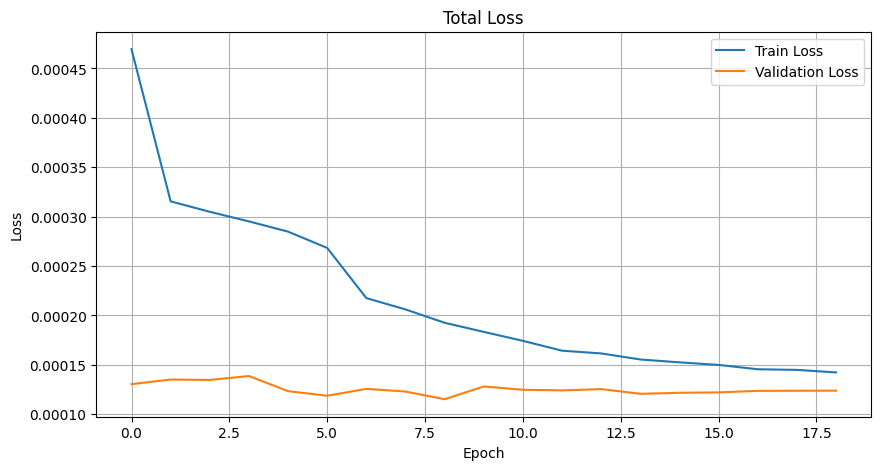

In [78]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(
    history.history["loss"],
    label="Train Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Total Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()

# PLOT

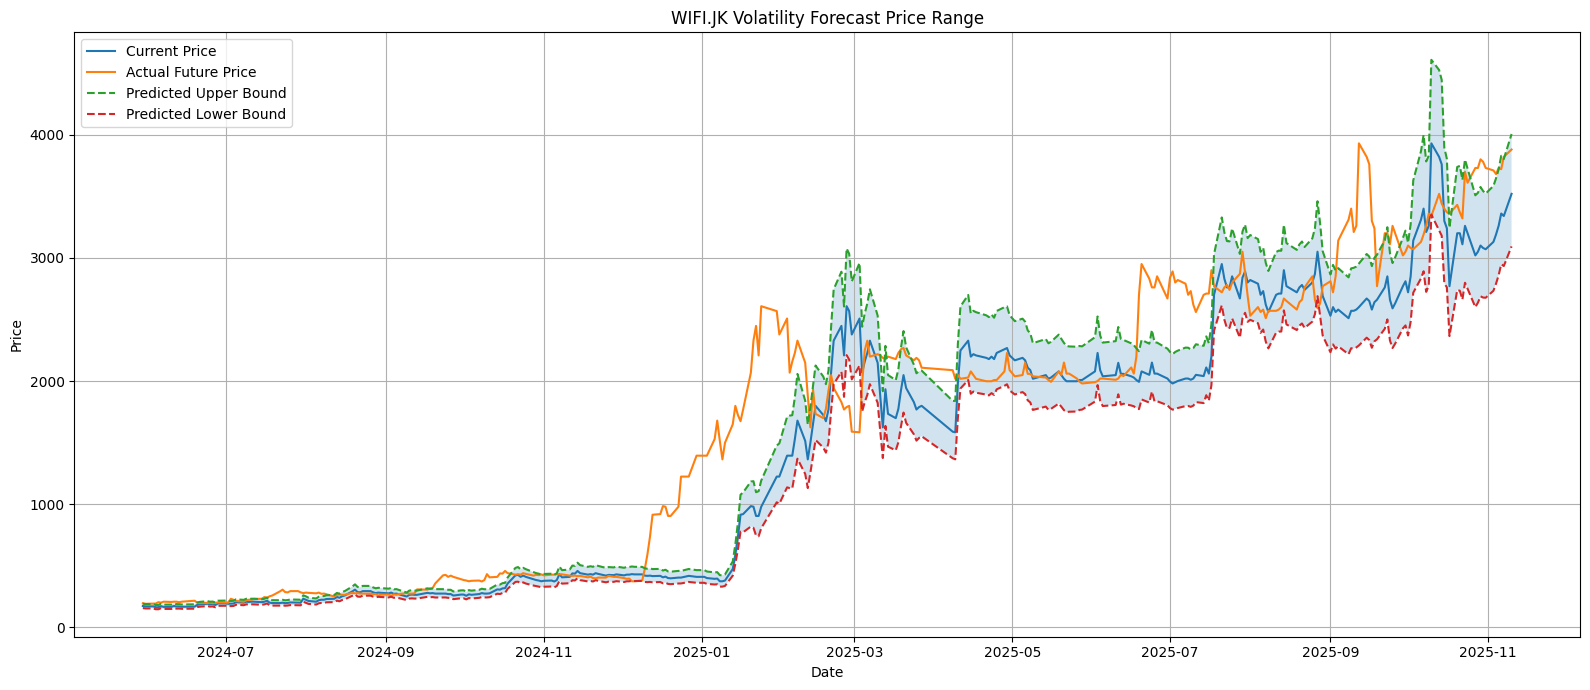

In [79]:
# ============================================================
# CONVERT VOLATILITY PREDICTION TO PRICE RANGE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# COPY PREDICTION DF
# ============================================================

plot_df = prediction_df.copy()

# ============================================================
# CHOOSE HORIZON
# ============================================================

HORIZON = 20

VOL_COL = "pred_1m"

# ============================================================
# GET CURRENT PRICE
# ============================================================

# ambil close asli dari combined_df
close_df = combined_df[[
    "date",
    "ticker",
    "close"
]].copy()

# merge ke prediction df
plot_df = plot_df.merge(

    close_df,

    on=["date", "ticker"],

    how="left"
)

# ============================================================
# ESTIMATE FUTURE PRICE RANGE
# ============================================================

plot_df["pred_upper_price"] = (

    plot_df["close"]

    *

    np.exp(
        plot_df[VOL_COL]
        *
        np.sqrt(HORIZON)
    )
)

plot_df["pred_lower_price"] = (

    plot_df["close"]

    *

    np.exp(
        -plot_df[VOL_COL]
        *
        np.sqrt(HORIZON)
    )
)

# ============================================================
# ACTUAL FUTURE PRICE
# ============================================================

plot_df["actual_future_price"] = (

    plot_df
    .groupby("ticker")["close"]
    .shift(-HORIZON)
)

# ============================================================
# REMOVE NAN
# ============================================================

plot_df = plot_df.dropna().reset_index(drop=True)

# ============================================================
# SELECT STOCK
# ============================================================

ticker = "WIFI.JK"

stock_df = (

    plot_df[
        plot_df["ticker"] == ticker
    ]

    .sort_values("date")
)

# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(16, 7))

# CURRENT PRICE
plt.plot(

    stock_df["date"],

    stock_df["close"],

    label="Current Price"
)

# ACTUAL FUTURE PRICE
plt.plot(

    stock_df["date"],

    stock_df["actual_future_price"],

    label="Actual Future Price"
)

# PREDICTED UPPER
plt.plot(

    stock_df["date"],

    stock_df["pred_upper_price"],

    linestyle="--",

    label="Predicted Upper Bound"
)

# PREDICTED LOWER
plt.plot(

    stock_df["date"],

    stock_df["pred_lower_price"],

    linestyle="--",

    label="Predicted Lower Bound"
)

# CONFIDENCE AREA
plt.fill_between(

    stock_df["date"],

    stock_df["pred_lower_price"],

    stock_df["pred_upper_price"],

    alpha=0.2
)

# ============================================================
# STYLE
# ============================================================

plt.title(
    f"{ticker} Volatility Forecast Price Range"
)

plt.xlabel("Date")

plt.ylabel("Price")

plt.legend()

plt.grid(True)

plt.tight_layout()

plt.show()

In [80]:
# ============================================================
# CALCULATE PREDICTED PRICE ERROR
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ============================================================
# REMOVE NAN
# ============================================================

eval_df = stock_df.dropna().copy()

# ============================================================
# MAE
# ============================================================

price_mae = mean_absolute_error(

    eval_df["actual_future_price"],

    (
        eval_df["pred_upper_price"]
        +
        eval_df["pred_lower_price"]
    ) / 2
)

# ============================================================
# RMSE
# ============================================================

price_rmse = np.sqrt(

    mean_squared_error(

        eval_df["actual_future_price"],

        (
            eval_df["pred_upper_price"]
            +
            eval_df["pred_lower_price"]
        ) / 2
    )
)

# ============================================================
# MAPE
# ============================================================

price_mape = np.mean(

    np.abs(

        (
            eval_df["actual_future_price"]

            -

            (
                eval_df["pred_upper_price"]
                +
                eval_df["pred_lower_price"]
            ) / 2
        )

        /

        eval_df["actual_future_price"]
    )

) * 100

# ============================================================
# R2 SCORE
# ============================================================

price_r2 = r2_score(

    eval_df["actual_future_price"],

    (
        eval_df["pred_upper_price"]
        +
        eval_df["pred_lower_price"]
    ) / 2
)

# ============================================================
# DIRECTIONAL ACCURACY
# ============================================================

actual_direction = np.sign(

    eval_df["actual_future_price"]

    -

    eval_df["close"]
)

predicted_direction = np.sign(

    (
        (
            eval_df["pred_upper_price"]
            +
            eval_df["pred_lower_price"]
        ) / 2
    )

    -

    eval_df["close"]
)

directional_accuracy = np.mean(

    actual_direction
    ==
    predicted_direction

) * 100

# ============================================================
# COVERAGE
# ============================================================

inside_range = (

    (
        eval_df["actual_future_price"]
        >=
        eval_df["pred_lower_price"]
    )

    &

    (
        eval_df["actual_future_price"]
        <=
        eval_df["pred_upper_price"]
    )
)

coverage = inside_range.mean() * 100

# ============================================================
# PRINT RESULTS
# ============================================================

print("=" * 60)
print("PRICE FORECAST EVALUATION")
print("=" * 60)

print(f"MAE                  : {price_mae:.4f}")

print(f"RMSE                 : {price_rmse:.4f}")

print(f"MAPE                 : {price_mape:.2f}%")

print(f"R2 Score             : {price_r2:.4f}")

print(f"Directional Accuracy : {directional_accuracy:.2f}%")

print(f"Range Coverage       : {coverage:.2f}%")

PRICE FORECAST EVALUATION
MAE                  : 275.8487
RMSE                 : 435.1367
MAPE                 : 17.37%
R2 Score             : 0.8617
Directional Accuracy : 69.63%
Range Coverage       : 53.30%


# SAVING MODEL

In [82]:
# ============================================================
# SAVE DEPLOYMENT ARTIFACTS
# ============================================================

import os
import json
import joblib
import zipfile
import pandas as pd
import tensorflow as tf

# ============================================================
# CUSTOM OBJECTS — required for model.save() / load_model()
# ============================================================

# TemporalAttentionPooling must be importable at load time.
# If it lives in another module, import it here instead.
custom_objects = {
    "TemporalAttentionPooling": TemporalAttentionPooling
}

# ============================================================
# CREATE DIRECTORY
# ============================================================

SAVE_DIR = "results/deployment_bundle"

os.makedirs(
    SAVE_DIR,
    exist_ok=True
)

# ============================================================
# SAVE FULL MODEL
# ============================================================

MODEL_PATH = os.path.join(
    SAVE_DIR,
    "multi_horizon_model.keras"
)

# FIX: save_format="keras" ensures custom layer is handled correctly.
# To load later:
#   tf.keras.models.load_model(MODEL_PATH, custom_objects=custom_objects)
results["model"].save(
    MODEL_PATH,
    save_format="keras"
)

print("Full model saved")

# ============================================================
# SAVE MODEL WEIGHTS
# ============================================================

WEIGHT_PATH = os.path.join(
    SAVE_DIR,
    "model.weights.h5"
)

results["model"].save_weights(
    WEIGHT_PATH
)

print("Model weights saved")

# ============================================================
# SAVE SCALERS
# ============================================================

joblib.dump(

    results["stock_scalers"],

    os.path.join(
        SAVE_DIR,
        "stock_scalers.pkl"
    )
)

print("Scalers saved")

# ============================================================
# SAVE LABEL ENCODERS
# ============================================================

joblib.dump(

    results["ticker_encoder"],

    os.path.join(
        SAVE_DIR,
        "ticker_encoder.pkl"
    )
)

joblib.dump(

    results["sector_encoder"],

    os.path.join(
        SAVE_DIR,
        "sector_encoder.pkl"
    )
)

joblib.dump(

    results["industry_encoder"],

    os.path.join(
        SAVE_DIR,
        "industry_encoder.pkl"
    )
)

print("Encoders saved")

# ============================================================
# SAVE DEPLOYMENT CONFIG
# ============================================================

with open(

    os.path.join(
        SAVE_DIR,
        "deployment_config.json"
    ),

    "w"

) as f:

    json.dump(

        results["deployment_config"],

        f,

        indent=4
    )

print("Deployment config saved")

# ============================================================
# SAVE FEATURE INFO
# ============================================================

feature_info = {

    "feature_cols": results["feature_cols"],

    "target_cols": results["target_cols"],

    "lookback": int(results["lookback"]),

    "num_stocks": int(results["num_stocks"]),

    "num_sectors": int(results["num_sectors"]),

    "num_industries": int(results["num_industries"])
}

with open(

    os.path.join(
        SAVE_DIR,
        "feature_info.json"
    ),

    "w"

) as f:

    json.dump(
        feature_info,
        f,
        indent=4
    )

print("Feature info saved")

# ============================================================
# SAVE TRAINING HISTORY
# ============================================================

history_obj = results["history"]

# ------------------------------------------------------------
# SUPPORT BOTH:
# 1. keras History object
# 2. manual dict history
# ------------------------------------------------------------

if hasattr(history_obj, "history"):

    history_df = pd.DataFrame(
        history_obj.history
    )

else:

    history_df = pd.DataFrame(
        history_obj
    )

history_df.to_csv(

    os.path.join(
        SAVE_DIR,
        "training_history.csv"
    ),

    index=False
)

print("Training history saved")

# ============================================================
# SAVE PREDICTIONS
# ============================================================

# FIX: y_test arrays are shape (-1, 1) from create_sequences(),
# so flatten() is required before creating the DataFrame.

prediction_df = pd.DataFrame({

    "date": results["test_dates"],

    "ticker": results["test_stock_ids"],

    # ========================================================
    # TRUE VALUES
    # ========================================================

    "true_10d": results["y_test_10d"].flatten(),

    "true_1m": results["y_test_1m"].flatten(),

    "true_3m": results["y_test_3m"].flatten(),

    # ========================================================
    # PREDICTIONS
    # ========================================================

    # pred arrays are already flattened in the training script
    "pred_10d": results["pred_10d"],

    "pred_1m": results["pred_1m"],

    "pred_3m": results["pred_3m"]
})

prediction_df.to_csv(

    os.path.join(
        SAVE_DIR,
        "test_predictions.csv"
    ),

    index=False
)

print("Predictions saved")

# ============================================================
# SAVE METRICS
# ============================================================

# FIX: sklearn returns np.float64 which is not JSON-serializable.
# Cast all metric values to plain Python float before dumping.

def _to_python_floats(d):
    return {k: float(v) for k, v in d.items()}

metrics = {

    "10d": _to_python_floats(results["metrics_10d"]),

    "1m": _to_python_floats(results["metrics_1m"]),

    "3m": _to_python_floats(results["metrics_3m"])
}

with open(

    os.path.join(
        SAVE_DIR,
        "metrics.json"
    ),

    "w"

) as f:

    json.dump(
        metrics,
        f,
        indent=4
    )

print("Metrics saved")

# ============================================================
# SAVE TENSORBOARD LOG LOCATION
# ============================================================

tensorboard_info = {

    "tensorboard_log_dir": results[
        "tensorboard_log_dir"
    ]
}

with open(

    os.path.join(
        SAVE_DIR,
        "tensorboard_info.json"
    ),

    "w"

) as f:

    json.dump(
        tensorboard_info,
        f,
        indent=4
    )

print("TensorBoard info saved")

# ============================================================
# SAVE MODEL SUMMARY
# ============================================================

summary_path = os.path.join(
    SAVE_DIR,
    "model_summary.txt"
)

with open(summary_path, "w") as f:

    results["model"].summary(

        print_fn=lambda x: f.write(x + "\n")
    )

print("Model summary saved")

# ============================================================
# SAVE CUSTOM OBJECT INFO
# ============================================================

custom_objects_info = {

    "custom_layer": "TemporalAttentionPooling",

    "load_snippet": (
        "tf.keras.models.load_model("
        "MODEL_PATH, "
        "custom_objects={'TemporalAttentionPooling': TemporalAttentionPooling}"
        ")"
    ),

    "framework": "TensorFlow/Keras"
}

with open(

    os.path.join(
        SAVE_DIR,
        "custom_objects.json"
    ),

    "w"

) as f:

    json.dump(
        custom_objects_info,
        f,
        indent=4
    )

print("Custom object info saved")

# ============================================================
# SAVE REQUIREMENTS
# ============================================================

requirements_text = """
tensorflow
numpy
pandas
scikit-learn
joblib
"""

with open(

    os.path.join(
        SAVE_DIR,
        "requirements.txt"
    ),

    "w"

) as f:

    f.write(requirements_text.strip())

print("Requirements saved")

# ============================================================
# ZIP EVERYTHING
# ============================================================

ZIP_PATH = "results/multi_horizon_deployment_bundle.zip"

with zipfile.ZipFile(

    ZIP_PATH,

    "w",

    zipfile.ZIP_DEFLATED

) as zipf:

    for root, dirs, files in os.walk(SAVE_DIR):

        for file in files:

            file_path = os.path.join(
                root,
                file
            )

            arcname = os.path.relpath(
                file_path,
                SAVE_DIR
            )

            zipf.write(
                file_path,
                arcname
            )

print("=" * 60)
print("DEPLOYMENT PACKAGE CREATED")
print("=" * 60)

print(f"ZIP FILE: {ZIP_PATH}")

Full model saved
Model weights saved
Scalers saved
Encoders saved
Deployment config saved
Feature info saved
Training history saved
Predictions saved
Metrics saved
TensorBoard info saved


Model summary saved
Custom object info saved
Requirements saved
DEPLOYMENT PACKAGE CREATED
ZIP FILE: results/multi_horizon_deployment_bundle.zip


# TENSORBOARD

In [1]:
%load_ext tensorboard
%tensorboard --logdir "tensorboard_logs/20260530-001040"

Launching TensorBoard...